# RSW / 02 — Hawkes vs Markov for MNQ 5-minute extremes: decay and next-bar forecast (2020-01 – 2023-06)

Protocol: [`RSW 003`](../../discussions/MNQ_Regime_Switching/003_claude_rsw02_hawkes_pot_preregistration.md). The event is |z_t| ≥ u, with u the 0.96 quantile of |z| on the fit window. z is the RSW 01 series.

- **H1 (decay)**: X = Σ_{k=6..60} [C(k) − C_null(k)] has a 95% lower bound > 0 against the binary chain and the simulated RSW M1 (2-state) and M2 (3-state) models. H1 is necessary, not sufficient: volatility persistence left in z also passes it (Markov smoke run).
- **H2 (forecast)**: HX, HXM or HP beats MC, M1 and M2 on the out-of-sample Bernoulli log score (Holm across 9 tests ≤ 0.05).
- **H3 (stable)**: the winner's branching ratio n is in (0.05, 0.95) in every fit, with a range ≤ 0.15.

In [1]:
import json, os, sys, tempfile, pickle
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RSW_SYNTHETIC") == "1"
SYNTH_HAWKES = os.environ.get("RSW_SYNTH_HAWKES") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RSW_SYNTH_DIR") or tempfile.mkdtemp(prefix="rsw_")
    os.environ["RSW_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P
from equity_trading import reversal as V
from equity_trading import regime_ar as R
from equity_trading import hawkes as H
from equity_trading import micro_bars as MB

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
RC, HC = R.RSWConfig(), H.HWKConfig()
D = dt.date
OUT = Path("02"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
print("engines", H.HWK_VERSION, R.RSW_VERSION, P.MRP_VERSION, "| synthetic" + (" hawkes" if SYNTH_HAWKES else " markov") if SYNTHETIC else "| real data")
if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    if SYNTH_HAWKES:
        H.write_synthetic_bursts(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG)
    else:
        R.write_synthetic_regimes(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.train[1], CFG)

engines 0.1.0 0.1.0 0.1.1 | real data


243,984 bars | observed 236,025 | u(0.96) = 2.122 | events 9,441 (0.0400 of observed bars)


by session                        by year                       
                 asia  london     ny    post    2020    2021   2022    2023
event rate     0.0346  0.0462  0.041  0.0411  0.0407  0.0418  0.038  0.0388

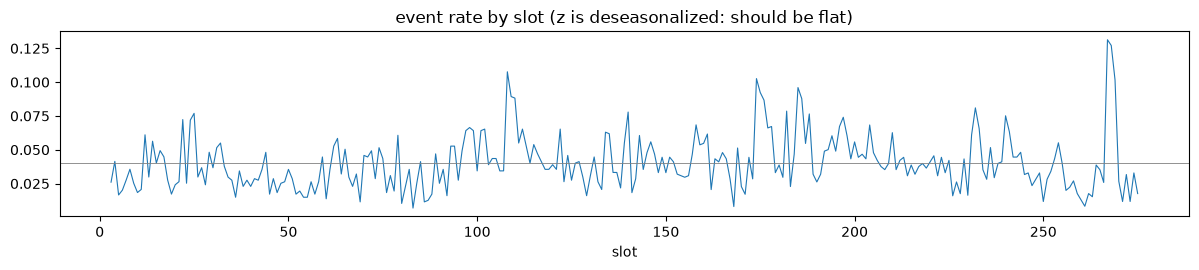

In [2]:
if SYNTHETIC:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2020, 7, 1)), CFG.refits_train, CFG.train[1]
else:
    FIRST_FIT, REFITS, END = (CFG.train[0], D(2021, 1, 1)), CFG.refits_train, CFG.train[1]
grid = P.load_grid(CFG.warmup_start, END, CFG)
sig2 = V.event_sigma(grid, FIRST_FIT, REFITS, END, CFG)
m1 = MB.load_1m(CFG.root, CFG.warmup_start - dt.timedelta(days=3), END + dt.timedelta(days=1))
S = R.build_series(grid, sig2, m1, CFG, RC)
S["z0"] = S["ret"] / np.sqrt(sig2.reindex(S.index).to_numpy(float))   # without the day rescale (sensitivity)
S = S[(S["trade_date"] >= CFG.train[0]) & (S["trade_date"] <= END)]
del m1, grid
td = S["trade_date"].to_numpy()
obs = S["obs"].to_numpy(bool)
ALL = np.ones(len(S), bool)
u_all = H.threshold(S, ALL, HC.q_main)
e_all, y_all = H.events(S, u_all)
print(f"{len(S):,} bars | observed {obs.sum():,} | u(0.96) = {u_all:.3f} | events {int(e_all.sum()):,} "
      f"({e_all[obs].mean():.4f} of observed bars)")
ev = pd.DataFrame({"e": e_all[obs], "slot": S["slot"].to_numpy()[obs], "session": S["session"].to_numpy()[obs],
                   "year": pd.to_datetime(S["trade_date"]).dt.year.to_numpy()[obs]})
display(pd.concat({"by session": ev.groupby("session")["e"].mean(), "by year": ev.groupby("year")["e"].mean()}).round(4).to_frame("event rate").T)
fig, ax = plt.subplots(figsize=(12, 2.8))
ev.groupby("slot")["e"].mean().plot(ax=ax, lw=0.8); ax.axhline(e_all[obs].mean(), color="grey", lw=0.6)
ax.set_title("event rate by slot (z is deseasonalized: should be flat)"); plt.tight_layout(); plt.show()

## 1. Test 1: decay of clustering against the Markov nulls

In [3]:
t0 = dt.datetime.now()
FULL = {K: R.fit(S, K, False, ALL, RC) for K in (2, 3)}   # descriptive refits on the whole window (the HMM nulls)
for K, m in FULL.items():
    print(f"M{K - 1} on the whole window"); display(m.table().round(4))
def nulls_for(fits, u):
    return {f"M{K - 1}": H.hmm_null_curve(m, u, HC.hmm_sim_bars, HC.kmax, seed=HC.seed) for K, m in fits.items()}
DEC = {}
for q in (HC.q_main,) + HC.q_sens:
    u = H.threshold(S, ALL, q)
    DEC[("z", q)] = H.decay_test(S, u, nulls_for(FULL, u), HC)
# sensitivity: z without the day rescale (HMM nulls refitted on z0)
S0 = S.assign(z=S["z0"], zl=np.where(S["has_lag"], np.r_[np.nan, S["z0"].to_numpy()[:-1]], 0.0))
u0 = H.threshold(S0, ALL, HC.q_main)
DEC[("z0", HC.q_main)] = H.decay_test(S0, u0, nulls_for({K: R.fit(S0, K, False, ALL, RC) for K in (2, 3)}, u0), HC)
dec_tab = pd.DataFrame({f"{c} q{q}": {k: v for k, v in d.items() if np.isscalar(v)} for (c, q), d in DEC.items()})
display(dec_tab)
print("elapsed", dt.datetime.now() - t0)

M1 on the whole window


,c,phi,sd,se_phi,p_stay,exp_duration_bars
state,,,,,,
0,0.0286,-0.0419,0.8295,0.0019,0.9420,17.2379
1,-0.2109,0.1366,2.1417,0.0098,0.4082,1.6898


M2 on the whole window


,c,phi,sd,se_phi,p_stay,exp_duration_bars
state,,,,,,
0,0.0441,-0.0643,0.6610,0.0026,0.9384,16.2281
1,0.0022,-0.0184,0.9977,0.0025,0.9623,26.5206
2,-0.2445,0.1935,2.5922,0.0157,0.3185,1.4674


,z q0.96,z q0.98,z q0.99,z0 q0.96
u,2.121795,2.578468,3.094889,1.959014
p,0.04,0.020002,0.010003,0.04
p11,0.083944,0.059724,0.052274,0.083997
p01,0.038243,0.019228,0.009596,0.038248
lambda_chain,0.045701,0.040496,0.042677,0.045749
events,9441,4721,2361,9441
excess_vs_base,0.197417,0.124627,0.032548,0.412971
excess_vs_chain,0.197417,0.124627,0.032548,0.412971
excess_vs_M1,0.262507,-0.016528,-0.166367,0.363343
excess_vs_M2,0.266642,0.123902,-0.059467,0.436464


elapsed 0:03:24.139859


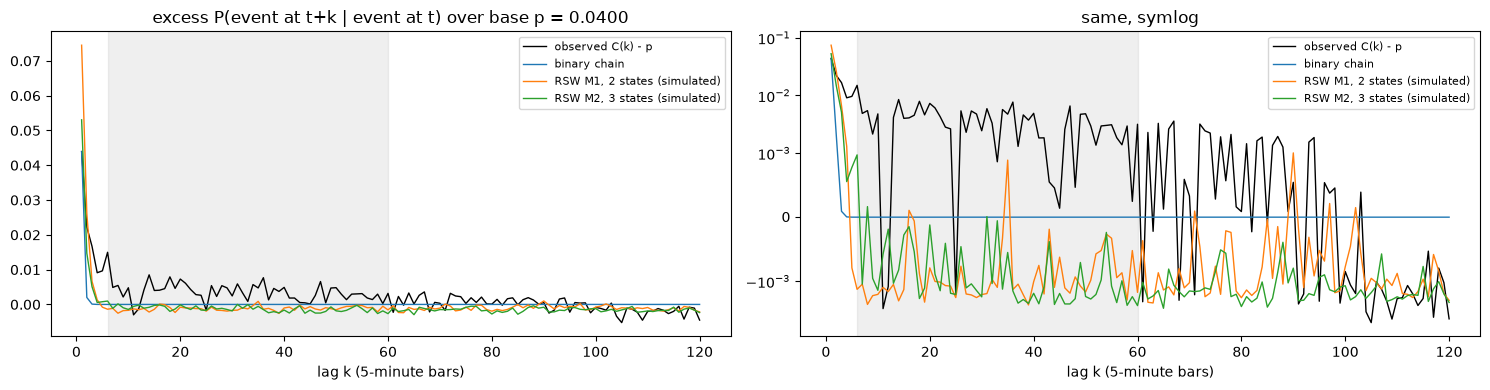

H1: True | X vs chain 0.1974 (lo95 0.1537) | X vs M1 0.2625 (lo95 0.2019) | X vs M2 0.2666 (lo95 0.2060)


In [4]:
d = DEC[("z", HC.q_main)]
k = np.arange(HC.kmax + 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for a, logy in zip(ax, (False, True)):
    a.plot(k[1:], (d["C"] - d["p"])[1:], label="observed C(k) - p", color="k", lw=1)
    a.plot(k[1:], (d["C_chain"] - d["p"])[1:], label="binary chain", lw=1)
    a.plot(k[1:], (d["C_M1"] - d["p"])[1:], label="RSW M1, 2 states (simulated)", lw=1)
    a.plot(k[1:], (d["C_M2"] - d["p"])[1:], label="RSW M2, 3 states (simulated)", lw=1)
    a.axvspan(*HC.excess_lags, color="grey", alpha=0.12)
    a.set_xlabel("lag k (5-minute bars)"); a.legend(fontsize=8)
    if logy:
        a.set_yscale("symlog", linthresh=1e-3); a.set_title("same, symlog")
    else:
        a.set_title(f"excess P(event at t+k | event at t) over base p = {d['p']:.4f}")
plt.tight_layout(); plt.savefig(OUT / "decay.png", dpi=110); plt.show()
H1 = d["H1"]
print("H1:", H1, "|", " | ".join(f"X vs {n} {d[f'excess_vs_{n}']:.4f} (lo95 {d[f'lo95_vs_{n}']:.4f})" for n in ("chain", "M1", "M2")))

## 2. Test 2: walk-forward next-bar forecast of an exceedance

In [5]:
KINDS = ("HX", "HXM", "HP")
cache = OUT / f"fits_{H.HWK_VERSION}{'_synth' if SYNTHETIC else ''}{'_hawkes' if SYNTH_HAWKES else ''}.pkl"
MSAR_FITS = {}
def walk(q):
    edges = list(REFITS) + [END + dt.timedelta(days=1)]
    out = {"e": [], "y": [], "u": [], "day": [], "idx": [], **{m: [] for m in ("B0", "MC", "M1", "M2") + KINDS},
           **{f"{kd}_ratio": [] for kd in KINDS}}
    fits = []
    for a, b in zip(edges[:-1], edges[1:]):
        fm = td < a
        u = H.threshold(S, fm, q)
        e, y = H.events(S, u)
        seg = (td >= a) & (td < b) & obs
        row = {"fit_before": str(a), "u": u}
        out["B0"].append(H.prob_constant(e, obs, fm)[seg])
        pc, chain = H.prob_chain(e, obs, fm); out["MC"].append(pc[seg]); row["chain"] = chain
        for K in (2, 3):
            if (a, K) not in MSAR_FITS:                 # the regime fits do not depend on the threshold
                MSAR_FITS[(a, K)] = R.fit(S, K, False, fm, RC)
            m = MSAR_FITS[(a, K)]
            out[f"M{K - 1}"].append(H.prob_msar(S, m, u)[seg]); row[f"M{K - 1}_phi"] = m.phi.tolist()
        for kd in KINDS:
            f = H.fit_hawkes(kd, e[fm], y[fm], obs[fm], u, HC)
            lam, exc = H.intensity(f, e, y)
            out[kd].append((1 - np.exp(-lam))[seg]); row[kd] = f
            out[f"{kd}_ratio"].append((lam / f.mu)[seg])
        out["e"].append(e[seg]); out["y"].append(y[seg]); out["u"].append(np.full(seg.sum(), u))
        out["day"].append(td[seg]); out["idx"].append(S.index[seg])
        fits.append(row)
        print(f"q {q} fit before {a}: u {u:.3f}, events in fit {int(e[fm & obs].sum())}, "
              + ", ".join(f"{kd} n={row[kd].n:.3f}" for kd in KINDS))
    return {k: (np.concatenate(v) if k != "idx" else np.concatenate([np.asarray(x) for x in v])) for k, v in out.items()}, fits
if cache.exists():
    WF = pickle.load(open(cache, "rb")); print("loaded", cache)
else:
    t0 = dt.datetime.now()
    WF = {q: walk(q) for q in (HC.q_main,) + HC.q_sens}
    pickle.dump(WF, open(cache, "wb")); print("elapsed", dt.datetime.now() - t0)
FC, FITS = WF[HC.q_main]
par = pd.DataFrame([{"fit_before": r["fit_before"], **r[kd].row()} for r in FITS for kd in KINDS])
display(par.round(4))
display(pd.DataFrame([{"fit_before": r["fit_before"], "u": r["u"], **r["chain"], "M1_phi": np.round(r["M1_phi"], 3),
                       "M2_phi": np.round(r["M2_phi"], 3)} for r in FITS]))

q 0.96 fit before 2021-01-01: u 2.136, events in fit 2731, HX n=0.109, HXM n=0.097, HP n=0.180
q 0.96 fit before 2022-01-01: u 2.143, events in fit 5507, HX n=0.130, HXM n=0.119, HP n=0.225
q 0.96 fit before 2023-01-01: u 2.125, events in fit 8058, HX n=0.119, HXM n=0.115, HP n=0.220
q 0.98 fit before 2021-01-01: u 2.582, events in fit 1366, HX n=0.085, HXM n=0.077, HP n=0.156
q 0.98 fit before 2022-01-01: u 2.605, events in fit 2754, HX n=0.105, HXM n=0.101, HP n=0.194
q 0.98 fit before 2023-01-01: u 2.590, events in fit 4029, HX n=0.100, HXM n=0.098, HP n=0.162
q 0.99 fit before 2021-01-01: u 3.109, events in fit 683, HX n=0.073, HXM n=0.070, HP n=0.125
q 0.99 fit before 2022-01-01: u 3.131, events in fit 1377, HX n=0.088, HXM n=0.087, HP n=0.114
q 0.99 fit before 2023-01-01: u 3.111, events in fit 2015, HX n=0.090, HXM n=0.090, HP n=0.095
elapsed 0:09:13.427280


,fit_before,kind,u,mu,n_branching,beta,delta,c,gamma,half_life_or_median_lag,loglik,events,n_obs,converged
0,2021-01-01,HX,2.1357,0.0366,0.1088,0.7049,0.0000,NaN,NaN,1.9818,-11403.8543,2731,68254,True
1,2021-01-01,HXM,2.1357,0.0371,0.0973,0.6389,0.3283,NaN,NaN,1.5471,-11393.0683,2731,68254,True
2,2021-01-01,HP,2.1357,0.0338,0.1796,NaN,0.0000,1.3980,0.5067,6.0000,-11399.4661,2731,68254,True
3,2022-01-01,HX,2.1429,0.0357,0.1298,0.7013,0.0000,NaN,NaN,1.9536,-22944.4003,5507,137667,True
4,2022-01-01,HXM,2.1429,0.0362,0.1191,0.6393,0.2368,NaN,NaN,1.5492,-22921.7350,5507,137667,True
5,2022-01-01,HP,2.1429,0.0320,0.2255,NaN,0.0000,0.8682,0.3919,6.0000,-22925.8558,5507,137667,True
6,2023-01-01,HX,2.1254,0.0362,0.1188,0.6514,0.0000,NaN,NaN,1.6173,-33580.1530,8058,201433,True
7,2023-01-01,HXM,2.1254,0.0363,0.1147,0.6201,0.1257,NaN,NaN,1.4502,-33565.3707,8058,201433,True
8,2023-01-01,HP,2.1254,0.0322,0.2201,NaN,0.0000,0.3359,0.2890,7.0000,-33559.1113,8058,201433,True


,fit_before,u,p01,p11,M1_phi,M2_phi
0,2021-01-01,2.135715,0.038587,0.074456,"[-0.058, 0.173]","[-0.073, -0.03, 0.281]"
1,2022-01-01,2.142890,0.038153,0.084564,"[-0.053, 0.124]","[-0.068, -0.029, 0.214]"
2,2023-01-01,2.125370,0.038113,0.085533,"[-0.042, 0.134]","[-0.062, -0.019, 0.19]"


In [6]:
def score_table(fc):
    e, day = fc["e"], fc["day"]
    sc = {m: H.bernoulli_score(fc[m], e) for m in ("B0", "MC", "M1", "M2") + KINDS}
    rows, pv = [], {}
    for kd in KINDS:
        row = {"model": kd, "score_per_bar": sc[kd].mean()}
        for bm in ("B0", "MC", "M1", "M2"):
            t = H.score_dm(sc[kd], sc[bm], day, HC.nw_lags)
            row[f"gain_vs_{bm}"], row[f"t_vs_{bm}"], row[f"p_vs_{bm}"] = t["per_bar_diff"], t["t"], t["p"]
            if bm != "B0":
                pv[(kd, bm)] = t["p"]
        rows.append(row)
    T = pd.DataFrame(rows).set_index("model")
    hp = R.holm({f"{a}|{b}": v for (a, b), v in pv.items()})
    for kd in KINDS:
        for bm in ("MC", "M1", "M2"):
            T.loc[kd, f"p_holm_vs_{bm}"] = hp[f"{kd}|{bm}"]
    T["passes_H2"] = np.logical_and.reduce([(T[f"gain_vs_{bm}"] > 0) & (T[f"p_holm_vs_{bm}"] <= HC.alpha)
                                            for bm in ("MC", "M1", "M2")])
    bench = pd.DataFrame({m: {"score_per_bar": sc[m].mean()} for m in ("B0", "MC", "M1", "M2")}).T
    return T, bench, sc
T, bench, SC = score_table(FC)
display(bench.round(6)); display(T.T)
H2 = bool(T["passes_H2"].any())
WIN = T.loc[T["passes_H2"], "score_per_bar"].idxmax() if H2 else None
print("H2:", H2, "| winner:", WIN)
for q in HC.q_sens:
    Tq, bq, _ = score_table(WF[q][0])
    print(f"--- sensitivity u(q={q}): events OOS {int(WF[q][0]['e'].sum())}")
    display(pd.concat([bq["score_per_bar"], Tq["score_per_bar"]]).to_frame(f"score q{q}").T)
    display(Tq[["gain_vs_MC", "gain_vs_M1", "gain_vs_M2", "p_holm_vs_MC", "p_holm_vs_M1", "p_holm_vs_M2", "passes_H2"]])

,score_per_bar
B0,-0.164405
MC,-0.163525
M1,-0.162660
M2,-0.162276


model,HX,HXM,HP
score_per_bar,-0.163207,-0.163529,-0.16309
gain_vs_B0,0.001198,0.000876,0.001315
t_vs_B0,7.509968,3.749832,7.780527
p_vs_B0,0.0,0.000088,0.0
gain_vs_MC,0.000318,-0.000004,0.000435
t_vs_MC,3.234145,0.032642,4.087318
p_vs_MC,0.00061,0.48698,0.000022
gain_vs_M1,-0.000547,-0.000869,-0.00043
t_vs_M1,-4.638973,-4.61966,-3.689675
p_vs_M1,0.999998,0.999998,0.999888


H2: False | winner: None
--- sensitivity u(q=0.98): events OOS 3269


,B0,MC,M1,M2,HX,HXM,HP
score q0.98,-0.096034,-0.095454,-0.094882,-0.094808,-0.095242,-0.095404,-0.095215


,gain_vs_MC,gain_vs_M1,gain_vs_M2,p_holm_vs_MC,p_holm_vs_M1,p_holm_vs_M2,passes_H2
model,,,,,,,
HX,0.000211,-0.000361,-0.000434,0.020095,1.0,1.0,False
HXM,0.000050,-0.000522,-0.000595,1.000000,1.0,1.0,False
HP,0.000238,-0.000334,-0.000407,0.016075,1.0,1.0,False


--- sensitivity u(q=0.99): events OOS 1613


,B0,MC,M1,M2,HX,HXM,HP
score q0.99,-0.054229,-0.053729,-0.053562,-0.053548,-0.053576,-0.053684,-0.053592


,gain_vs_MC,gain_vs_M1,gain_vs_M2,p_holm_vs_MC,p_holm_vs_M1,p_holm_vs_M2,passes_H2
model,,,,,,,
HX,0.000153,-0.000014,-0.000029,0.053672,1.0,1.0,False
HXM,0.000045,-0.000122,-0.000136,1.000000,1.0,1.0,False
HP,0.000137,-0.000029,-0.000044,0.070317,1.0,1.0,False


H3: False | HX branching ratio per fit [0.109 0.13  0.119] | half-life / median lag per fit [2.0, 2.0, 1.6]
--- MC: lift in the top 5% of predicted probability {'top_share': 0.05, 'rate_top': 0.0757, 'rate_all': 0.0389, 'lift': 1.9466, 'share_of_events_caught': 0.0973}
--- M1: lift in the top 5% of predicted probability {'top_share': 0.05, 'rate_top': 0.0846, 'rate_all': 0.0389, 'lift': 2.1765, 'share_of_events_caught': 0.1088}
--- M2: lift in the top 5% of predicted probability {'top_share': 0.05, 'rate_top': 0.0825, 'rate_all': 0.0389, 'lift': 2.1213, 'share_of_events_caught': 0.1061}
--- HX: lift in the top 5% of predicted probability {'top_share': 0.05, 'rate_top': 0.0823, 'rate_all': 0.0389, 'lift': 2.1152, 'share_of_events_caught': 0.1058}


MC                       M1                     M2                     HX               
     mean_p    rate        n  mean_p    rate      n  mean_p    rate      n  mean_p    rate      n
bin                                                                                              
0    0.0381  0.0358  94683.0  0.0318  0.0278  16778  0.0263  0.0241  16778  0.0351  0.0306  16778
1    0.0386  0.0386  66575.0  0.0323  0.0313  16777  0.0298  0.0254  16777  0.0351  0.0361  16777
2    0.0804  0.0861   6513.0  0.0329  0.0293  16777  0.0318  0.0305  16777  0.0354  0.0331  16777
3       NaN     NaN      NaN  0.0333  0.0339  16777  0.0339  0.0339  16777  0.0357  0.0355  19355
4       NaN     NaN      NaN  0.0338  0.0348  16777  0.0358  0.0377  16777  0.0359  0.0311  14199
5       NaN     NaN      NaN  0.0346  0.0355  16777  0.0377  0.0365  16777  0.0359  0.0350  16777
6       NaN     NaN      NaN  0.0359  0.0359  16777  0.0394  0.0392  16777  0.0363  0.0395  16777
7       NaN     NaN      NaN  0.0383  0.0420  16777  0.0412  0.0443  16777  0.0383  0.0380  16777
8       NaN     NaN      NaN  0.0442  0.0490  16777  0.0439  0.0501  16777  0.0455  0.0437  16777
9       NaN     NaN      NaN  0.0794  0.0694  16777  0.0671  0.0672  16777  0.0657  0.0654  16777

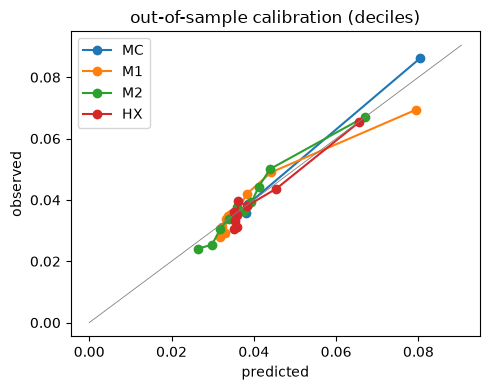

In [7]:
ref = WIN or "HX"
ns = [r[ref].n for r in FITS]
H3 = bool(H2 and all(HC.stab_lo < n_ < HC.stab_hi for n_ in ns) and (max(ns) - min(ns) <= HC.stab_range))
print(f"H3: {H3} | {ref} branching ratio per fit {np.round(ns, 3)} | half-life / median lag per fit",
      [round(r[ref].half_life_bars, 1) for r in FITS])
e = FC["e"]
for m in ("MC", "M1", "M2", ref):
    print(f"--- {m}: lift in the top {HC.lift_top:.0%} of predicted probability", {k: round(v, 4) for k, v in H.lift(FC[m], e, HC.lift_top).items()})
cal = pd.concat({m: H.calibration(FC[m], e) for m in ("MC", "M1", "M2", ref)}, axis=1)
display(cal.round(4))
fig, ax = plt.subplots(figsize=(5, 4))
for m in ("MC", "M1", "M2", ref):
    c = H.calibration(FC[m], e); ax.plot(c["mean_p"], c["rate"], marker="o", label=m)
lim = max(cal.xs("rate", axis=1, level=1).max().max(), 0.01) * 1.05
ax.plot([0, lim], [0, lim], color="grey", lw=0.6); ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend()
ax.set_title("out-of-sample calibration (deciles)"); plt.tight_layout(); plt.savefig(OUT / "calibration.png", dpi=110); plt.show()

## 3. Sizes: GPD of the exceedances, and whether they grow with excitation (κ)

In [8]:
edges = list(REFITS) + [END + dt.timedelta(days=1)]
gp = []
for r, a in zip(FITS, edges[:-1]):
    fm = (td < a)
    u = r["u"]; e_, y_ = H.events(S, u)
    lam, _ = H.intensity(r[ref], e_, y_)
    sel = fm & (e_ > 0)
    gp.append({"fit_before": r["fit_before"], "u": u, **H.gpd_fit(y_[sel] - u, lam[sel] / r[ref].mu)})
gp = pd.DataFrame(gp); display(gp.round(4))
sel = FC["e"] > 0
g_oos = H.gpd_fit((FC["y"] - FC["u"])[sel], FC[f"{ref}_ratio"][sel])
print(f"out of sample ({ref} intensity):", {k: round(v, 4) for k, v in g_oos.items()})

,fit_before,u,xi,sigma,n,xi_k,sigma0_k,kappa,lr,p_kappa0
0,2021-01-01,2.1357,0.2027,0.6087,2731,0.2003,0.5842,0.3154,10.3280,0.0013
1,2022-01-01,2.1429,0.2096,0.6227,5507,0.2013,0.5863,0.3897,45.6416,0.0000
2,2023-01-01,2.1254,0.2458,0.6102,8058,0.2375,0.5757,0.4087,69.0428,0.0000


out of sample (HX intensity): {'xi': 0.279, 'sigma': 0.5885, 'n': 6524, 'xi_k': 0.2703, 'sigma0_k': 0.5533, 'kappa': 0.4467, 'lr': 55.8904, 'p_kappa0': 0.0}


In [9]:
# descriptive: sign persistence of consecutive exceedances within 12 bars (direction is not tested)
zz = S["z"].to_numpy(float); ii = np.flatnonzero(e_all > 0)
gap = np.diff(ii); same = np.sign(zz[ii[1:]]) == np.sign(zz[ii[:-1]])
near = gap <= 12
print(f"pairs within 12 bars: {near.sum():,} | same sign {same[near].mean():.3f} | pairs further apart: same sign {same[~near].mean():.3f}"
      f" | share of exceedances that are negative {np.mean(zz[ii] < 0):.3f}")

pairs within 12 bars: 4,023 | same sign 0.595 | pairs further apart: same sign 0.526 | share of exceedances that are negative 0.544


## 4. Verdict

In [10]:
verdict = ("HAWKES (burst timing forecastable beyond Markov; next: use pre-registration)" if (H1 and H2 and H3) else
           "SLOW_CLUSTERING_NO_FORECAST_GAIN (Hawkes or leftover volatility persistence: not identified)" if (H1 and not H2) else
           "SHORT_RUN_HAWKES_FORECAST_ONLY" if (H2 and not H1) else
           "HAWKES_BUT_UNSTABLE" if (H1 and H2) else "MARKOV_SUFFICES")
print("H1", H1, "| H2", H2, "| H3", H3, "|", verdict)
summary = {"study": "RSW 02", "engine": H.HWK_VERSION, "synthetic": SYNTHETIC, "synthetic_hawkes": SYNTH_HAWKES,
           "u_full": u_all, "events_full": int(e_all.sum()),
           "decay": {f"{c}_q{q}": {k: v for k, v in d_.items() if np.isscalar(v)} for (c, q), d_ in DEC.items()},
           "decay_curve": {k_: DEC[("z", HC.q_main)][k_].tolist() for k_ in ("C", "C_chain", "C_M1", "C_M2")},
           "params": json.loads(par.to_json(orient="records")),
           "scores_benchmarks": bench["score_per_bar"].to_dict(), "scores": json.loads(T.to_json(orient="index")),
           "winner": WIN, "branching_ratio_per_fit": ns, "gpd": json.loads(gp.to_json(orient="records")),
           "gpd_oos": g_oos,
           "lift": {m: H.lift(FC[m], FC["e"], HC.lift_top) for m in ("MC", "M1", "M2", ref)},
           "H1": H1, "H2": H2, "H3": H3, "verdict": verdict}
json.dump(summary, open(OUT / "summary.json", "w"), indent=1, default=str)
print("written", OUT / "summary.json")

H1 True | H2 False | H3 False | SLOW_CLUSTERING_NO_FORECAST_GAIN (Hawkes or leftover volatility persistence: not identified)
written 02\summary.json
